**PART 1**

In [4]:
!pip install -q pypdf tiktoken sentence-transformers faiss-cpu google-genai pandas matplotlib

In [5]:
import os, re, json, time, textwrap
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pypdf import PdfReader
import tiktoken
from sentence_transformers import SentenceTransformer
import faiss

pd.set_option("display.max_colwidth", 120)
print("All libraries imported successfully.")

All libraries imported successfully.


In [25]:
PDF_PATH       = "/troubleshooting_runbook.pdf"

CHUNK_SIZE     = 300    # tokens per chunk   (use 800  for a full-length book)
CHUNK_OVERLAP  = 60     # tokens shared between neighbouring chunks (use 120 for a book)

EMBED_MODEL    = "sentence-transformers/all-MiniLM-L6-v2"
LLM_MODEL      = "gemini-3.6-flash"

DEFAULT_TOP_K  = 5
INDEX_DIR      = "rag_index"

print(f"Knowledge source : {PDF_PATH}")
print(f"Chunking         : {CHUNK_SIZE} tokens, overlap {CHUNK_OVERLAP}")
print(f"Embedding model  : {EMBED_MODEL}")
print(f"LLM              : {LLM_MODEL}")

Knowledge source : /troubleshooting_runbook.pdf
Chunking         : 300 tokens, overlap 60
Embedding model  : sentence-transformers/all-MiniLM-L6-v2
LLM              : gemini-3.6-flash


In [6]:
reader = PdfReader(PDF_PATH)
num_pages = len(reader.pages)

print(f"Loaded '{PDF_PATH}'")
print(f"Number of pages : {num_pages}")
print("Metadata        :")
for key, value in (reader.metadata or {}).items():
    print(f"   {key:<16} {value}")

Loaded '/troubleshooting_runbook.pdf'
Number of pages : 7
Metadata        :
   /Author          (anonymous)
   /CreationDate    D:20261111031031+00'00'
   /Creator         (unspecified)
   /Keywords        
   /ModDate         D:20261111031031+00'00'
   /Producer        ReportLab PDF Library - (opensource)
   /Subject         (unspecified)
   /Title           Contoso Platform Troubleshooting Runbook
   /Trapped         /False


In [7]:
pages = []          # list of {"page": int, "text": str}
for i, page in enumerate(reader.pages, start=1):
    raw = page.extract_text() or ""        # some pages (images, blank) may return None
    pages.append({"page": i, "text": raw})

print(f"Extracted text from {len(pages)} pages.\n")
print("=== Raw text of page 1 (first 900 characters) ===")
print(pages[0]["text"][:900])

Extracted text from 7 pages.

=== Raw text of page 1 (first 900 characters) ===
Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo data
Page 1
Contoso Platform Troubleshooting Runbook
Document owner: Platform Reliability Team  |  Version: 3.2  |  Last reviewed: 2026-10-15
1. Purpose and scope
This runbook gives on-call engineers a consistent way to diagnose and resolve production incidents
across the eight core Contoso services: payment-gateway, auth-service, order-api, inventory-service,
notification-service, search-service, reporting-engine and user-profile-api. It covers the ten most frequent
error codes seen in the incident log over the last two quarters. Each error code has a symptom description,
likely causes, a diagnostic checklist, a fix, and a prevention note.
2. How to use this runbook
Start from the error code in the alert or log line. Confirm the symptom matches, work through the
diagnostic checklist in order, and app


,page,chars,words,lines,empty?
0,1,2277,326,68,False
1,2,1893,294,55,False
2,3,2267,354,32,False
3,4,2651,409,36,False
4,5,2711,371,39,False
5,6,2681,380,36,False
6,7,2103,313,63,False



Total words      : 2,447
Average per page : 350 words
Empty pages      : 0


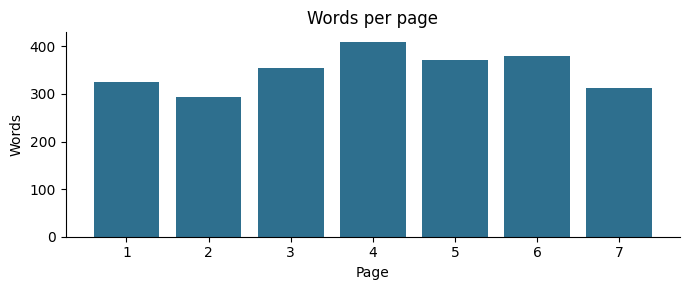

In [8]:
# ---- 1.3a  Per-page statistics ----
stats = pd.DataFrame({
    "page":  [p["page"] for p in pages],
    "chars": [len(p["text"]) for p in pages],
    "words": [len(p["text"].split()) for p in pages],
    "lines": [p["text"].count("\n") for p in pages],
})
stats["empty?"] = stats["chars"] < 50
display(stats)

total_words = stats["words"].sum()
print(f"\nTotal words      : {total_words:,}")
print(f"Average per page : {stats['words'].mean():.0f} words")
print(f"Empty pages      : {int(stats['empty?'].sum())}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(stats["page"], stats["words"], color="#2E6F8E")
ax.set_xlabel("Page"); ax.set_ylabel("Words"); ax.set_title("Words per page")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [9]:
# ---- 1.3b  How long is the document in TOKENS? ----
# tiktoken's cl100k_base is the tokenizer used by many modern LLMs. Gemini tokenizes
# slightly differently, but the counts are close enough to plan chunk sizes.
enc = tiktoken.get_encoding("cl100k_base")

def count_tokens(text: str) -> int:
    return len(enc.encode(text))

total_tokens = sum(count_tokens(p["text"]) for p in pages)
print(f"Total tokens in document : {total_tokens:,}")
print(f"Tokens per word (ratio)  : {total_tokens / total_words:.2f}")

sample = "Lock wait timeout exceeded; try restarting transaction."
print(f"\nExample: {sample!r}")
print(f"  words  = {len(sample.split())}")
print(f"  tokens = {count_tokens(sample)}  ->  {[enc.decode([t]) for t in enc.encode(sample)]}")

Total tokens in document : 3,837
Tokens per word (ratio)  : 1.57

Example: 'Lock wait timeout exceeded; try restarting transaction.'
  words  = 7
  tokens = 9  ->  ['Lock', ' wait', ' timeout', ' exceeded', ';', ' try', ' restarting', ' transaction', '.']


In [10]:
# ---- 1.3c  Text quality issues ----
all_text = "\n".join(p["text"] for p in pages)

# (1) Lines repeated on many pages = headers / footers that add noise to every chunk
def find_repeated_lines(pages, min_fraction=0.5):
    """Lines that occur on at least `min_fraction` of the pages (counted once per page)."""
    line_pages = Counter()
    for p in pages:
        for line in {l.strip() for l in p["text"].split("\n") if l.strip()}:
            line_pages[line] += 1
    threshold = max(2, int(len(pages) * min_fraction))
    return {ln: c for ln, c in line_pages.items() if c >= threshold}

repeated = find_repeated_lines(pages)
print("1) Lines repeated on most pages (likely header/footer noise):")
for ln, c in repeated.items():
    print(f"   on {c} pages: {ln[:90]}")

# (2) Page-number lines
page_num_lines = re.findall(r"^Page \d+$", all_text, flags=re.MULTILINE)
print(f"\n2) Standalone 'Page N' lines found: {len(page_num_lines)}")

# (3) Lines broken mid-sentence (line ends without punctuation and next line starts lowercase)
broken = re.findall(r"[a-z,]\n[a-z]", all_text)
print(f"3) Mid-sentence line breaks: {len(broken)}  (e.g. 'within five minutes of\\nacknowledging')")

# (4) Table cells extracted one per line (very short lines in a row)
short_runs = re.findall(r"(?:^.{1,25}\n){4,}", all_text, flags=re.MULTILINE)
print(f"4) Runs of 4+ very short lines (tables flattened into single cells): {len(short_runs)}")
print("   example:", repr(short_runs[0][:80]) if short_runs else "none")

# (5) Non-ASCII / special characters that embeddings may treat oddly
odd_chars = Counter(ch for ch in all_text if ord(ch) > 126)
print(f"5) Non-ASCII characters: {dict(odd_chars) if odd_chars else 'none'}")

# (6) Hyphenated line-break words (e.g. 'configu-\\nration') – common in typeset books
hyphen_breaks = re.findall(r"\w-\n\w", all_text)
print(f"6) Hyphenated line breaks: {len(hyphen_breaks)}")

1) Lines repeated on most pages (likely header/footer noise):
   on 7 pages: Contoso Platform Engineering | Troubleshooting Runbook v3.2 | Internal - Synthetic demo da

2) Standalone 'Page N' lines found: 7
3) Mid-sentence line breaks: 90  (e.g. 'within five minutes of\nacknowledging')
4) Runs of 4+ very short lines (tables flattened into single cells): 6
   example: '3. Service map\nService\nDomain\nOwning team\nPrimary datastore\nCritical dependency\n'
5) Non-ASCII characters: none
6) Hyphenated line breaks: 0


In [11]:
REPEATED_LINES = list(repeated)      # the header/footer lines detected above

def clean_page_text(text: str, footer_lines=None) -> str:
    footer_lines = REPEATED_LINES if footer_lines is None else footer_lines
    # 1) drop repeated header/footer lines and standalone page numbers
    for ln in footer_lines:
        text = re.sub(rf"^{re.escape(ln)}\s*$", "", text, flags=re.MULTILINE)
    text = re.sub(r"^Page \d+\s*$", "", text, flags=re.MULTILINE)
    # 6) re-join hyphenated line breaks:  configu-\nration -> configuration
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)
    # 5) normalise fancy quotes / dashes to plain ASCII
    text = (text.replace("’", "'").replace("‘", "'")
                .replace("“", '"').replace("”", '"')
                .replace("–", "-").replace("—", "-"))
    # 3) join lines that are clearly mid-sentence (line ends in letter/comma, next starts lowercase)
    text = re.sub(r"([a-z,;])\n([a-z])", r"\1 \2", text)
    # 4) collapse runs of very short lines (flattened table cells) into one line separated by ' | '
    #    (only when the current line does not end a sentence, so headings after a paragraph stay separate)
    text = re.sub(r"(?<=[^\s.:!?])\n(?=.{1,25}\n)", " | ", text)
    # tidy whitespace but keep paragraph structure
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

for p in pages:
    p["clean"] = clean_page_text(p["text"])

before = sum(count_tokens(p["text"])  for p in pages)
after  = sum(count_tokens(p["clean"]) for p in pages)
print(f"Tokens before cleaning : {before:,}")
print(f"Tokens after cleaning  : {after:,}   ({100*(before-after)/before:.1f}% removed)\n")
print("=== Cleaned text of page 2 (first 700 chars) ===")
print(pages[1]["clean"][:700])

Tokens before cleaning : 3,837
Tokens after cleaning  : 3,549   (7.5% removed)

=== Cleaned text of page 2 (first 700 chars) ===
Severity and Escalation | 5. Severity matrix | Severity | Definition | Ack target | Update cadence | Escalate to | Sev1
Full outage or data loss risk; revenue or security impact | 5 min | Every 15 min
Engineering Manager + Director on-call | Sev2
Major feature degraded for many users; workaround limited | 10 min | Every 30 min | Engineering Manager | Sev3
Partial degradation, workaround available | 30 min | Every 2 hours | Owning team lead | Sev4
Minor issue, cosmetic or single-user | Next business day | Daily | Owning team backlog | 6. Escalation procedure
The primary on-call engineer owns the incident until a named incident commander takes over. For Sev1
and Sev2 incidents an incident comm


In [12]:
def chunk_pages(pages, chunk_size: int, overlap: int):
    """Token-based sliding-window chunker that remembers page numbers."""
    assert 0 <= overlap < chunk_size, "overlap must be smaller than chunk_size"
    # 1) Flatten the document into one token stream, remembering the page of every token.
    tokens, token_pages = [], []
    for p in pages:
        ids = enc.encode(p["clean"] + "\n\n")          # paragraph gap between pages
        tokens.extend(ids)
        token_pages.extend([p["page"]] * len(ids))

    # 2) Slide the window.
    chunks, start, step = [], 0, chunk_size - overlap
    while start < len(tokens):
        end = min(start + chunk_size, len(tokens))
        window_pages = sorted(set(token_pages[start:end]))
        chunks.append({
            "chunk_id":   len(chunks),
            "text":       enc.decode(tokens[start:end]).strip(),
            "pages":      window_pages,
            "page_label": f"p.{window_pages[0]}" if len(window_pages) == 1
                          else f"pp.{window_pages[0]}-{window_pages[-1]}",
            "n_tokens":   end - start,
        })
        if end == len(tokens):
            break
        start += step
    return chunks

chunks = chunk_pages(pages, CHUNK_SIZE, CHUNK_OVERLAP)
print(f"Created {len(chunks)} chunks of ≤{CHUNK_SIZE} tokens with {CHUNK_OVERLAP}-token overlap.\n")

chunk_df = pd.DataFrame([{ "chunk_id": c["chunk_id"], "pages": c["page_label"],
                           "tokens": c["n_tokens"], "preview": c["text"][:90].replace("\n", " ") + "…"}
                         for c in chunks])
display(chunk_df)

Created 15 chunks of ≤300 tokens with 60-token overlap.



,chunk_id,pages,tokens,preview
0,0,p.1,300,Contoso Platform Troubleshooting Runbook Document owner: Platform Reliability Team | Versi…
1,1,pp.1-2,300,"Phoenix | PostgreSQL (payments-db) Bank API, auth-service auth-service | Identity | Team S…"
2,2,p.2,300,| Ack target | Update cadence | Escalate to | Sev1 Full outage or data loss risk; revenue …
3,3,pp.2-3,300,Identify the error code and service from the alert payload. 3. Check the deploy dashboard:…
4,4,p.3,300,access token TTL shortened in config; (b) clock skew above 30 seconds between services; (c…
5,5,pp.3-4,300,ucket policy per API key. Likely causes: A batch job calling without backoff; a retry stor…
6,6,p.4,300,Null or missing field in a new payload shape; an unhandled promise rejection or exception …
7,7,pp.4-5,300,. 2. Test connectivity from a debug pod (curl with timing). 3. Confirm circuit breaker sta…
8,8,pp.4-5,300,"status. Fix: Restore any missing index, set explicit client timeouts, scale out replicas, …"
9,9,p.5,300,missing index and standardise lock ordering. Set idle_in_transaction_session_timeout to 60…


In [13]:
# Look at one complete chunk and verify the overlap with its neighbour
i = 2
print(f"=== Chunk {i}  ({chunks[i]['page_label']}, {chunks[i]['n_tokens']} tokens) ===")
print(chunks[i]["text"])
print("\n=== Overlap check: the END of chunk", i, "should reappear at the START of chunk", i+1, "===")
print("end of chunk", i, ":", repr(chunks[i]["text"][-120:]))
print("start of chunk", i+1, ":", repr(chunks[i+1]["text"][:120]))

=== Chunk 2  (p.2, 300 tokens) ===
| Ack target | Update cadence | Escalate to | Sev1
Full outage or data loss risk; revenue or security impact | 5 min | Every 15 min
Engineering Manager + Director on-call | Sev2
Major feature degraded for many users; workaround limited | 10 min | Every 30 min | Engineering Manager | Sev3
Partial degradation, workaround available | 30 min | Every 2 hours | Owning team lead | Sev4
Minor issue, cosmetic or single-user | Next business day | Daily | Owning team backlog | 6. Escalation procedure
The primary on-call engineer owns the incident until a named incident commander takes over. For Sev1
and Sev2 incidents an incident commander must be assigned within 15 minutes. The commander does not debug; they coordinate, keep the timeline, and manage stakeholder communication. If the primary on-call has not acknowledged an alert within the ack target, the page automatically escalates to the secondary on-call and then to the team lead.
7. Standard first five minu

In [14]:
rows = []
for size, ov in [(150, 30), (200, 40), (300, 60), (500, 100), (800, 150), (1000, 150)]:
    cs = chunk_pages(pages, size, ov)
    sections_per_chunk = [c["text"].count("Symptom:") for c in cs]      # one 'Symptom:' per error-code section
    rows.append({"chunk_size": size, "overlap": ov, "num_chunks": len(cs),
                 "avg tokens": round(np.mean([c["n_tokens"] for c in cs])),
                 "max sections in one chunk": max(sections_per_chunk),
                 "chunks mixing 2+ sections": sum(1 for s in sections_per_chunk if s >= 2)})
display(pd.DataFrame(rows))

,chunk_size,overlap,num_chunks,avg tokens,max sections in one chunk,chunks mixing 2+ sections
0,150,30,30,147,1,0
1,200,40,22,200,2,1
2,300,60,15,293,2,3
3,500,100,9,483,3,5
4,800,150,6,716,4,4
5,1000,150,4,1000,5,3


**Part 2 — Embedding & Vector Database**

In [15]:
embedder = SentenceTransformer(EMBED_MODEL)
print(f"Loaded {EMBED_MODEL}")
print(f"Embedding dimension : {embedder.get_sentence_embedding_dimension()}")
print(f"Max sequence length : {embedder.max_seq_length} word-pieces\n")

toy = [
    "The container was killed because it ran out of memory.",   # A
    "Pods restart repeatedly with reason OOMKilled, exit code 137.",  # B  (same meaning as A, different words)
    "The TLS certificate has expired and SSL handshakes fail.",  # C  (different topic)
    "What is the ack target for a Sev1 incident?",              # D  (different topic)
]
toy_vecs = embedder.encode(toy, normalize_embeddings=True)
print("Shape of the embedding matrix:", toy_vecs.shape, "(4 sentences × 384 numbers)")
print("First 8 numbers of sentence A:", np.round(toy_vecs[0][:8], 3), "…\n")

# With normalised vectors, the dot product IS the cosine similarity.
sim = toy_vecs @ toy_vecs.T
labels = ["A: OOM (plain words)", "B: OOMKilled (jargon)", "C: TLS expired", "D: Sev1 ack target"]
display(pd.DataFrame(np.round(sim, 2), index=labels, columns=["A", "B", "C", "D"]))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

Loaded sentence-transformers/all-MiniLM-L6-v2
Embedding dimension : 384
Max sequence length : 256 word-pieces



/tmp/ipykernel_1036/2498197638.py:3: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(f"Embedding dimension : {embedder.get_sentence_embedding_dimension()}")


Shape of the embedding matrix: (4, 384) (4 sentences × 384 numbers)
First 8 numbers of sentence A: [ 0.084  0.093 -0.027  0.017  0.125 -0.071 -0.025  0.045] …



,A,B,C,D
A: OOM (plain words),1.00,0.43,0.15,0.19
B: OOMKilled (jargon),0.43,1.00,0.21,0.13
C: TLS expired,0.15,0.21,1.00,0.13
D: Sev1 ack target,0.19,0.13,0.13,1.00


In [16]:
chunk_texts = [c["text"] for c in chunks]

t0 = time.time()
chunk_vecs = embedder.encode(chunk_texts, normalize_embeddings=True,
                             batch_size=32, show_progress_bar=True)
chunk_vecs = np.asarray(chunk_vecs, dtype="float32")   # FAISS wants float32
print(f"\nEmbedded {chunk_vecs.shape[0]} chunks into {chunk_vecs.shape[1]}-d vectors in {time.time()-t0:.1f}s")
print("Every vector has length 1.0?  ", np.allclose(np.linalg.norm(chunk_vecs, axis=1), 1.0))

Batches:   0%|          | 0/1 [00:00<?, ?it/s]


Embedded 15 chunks into 384-d vectors in 6.0s
Every vector has length 1.0?   True


In [17]:
dim = chunk_vecs.shape[1]
index = faiss.IndexFlatIP(dim)        # IP = inner product = cosine (vectors are normalised)
index.add(chunk_vecs)                 # positions 0..N-1 line up with the `chunks` list

print(f"FAISS index built: {index.ntotal} vectors of dimension {dim}")
print(f"Index type        : {type(index).__name__} (exact search)")

# ---- Persist to disk ----
os.makedirs(INDEX_DIR, exist_ok=True)
faiss.write_index(index, f"{INDEX_DIR}/chunks.faiss")
with open(f"{INDEX_DIR}/chunks.json", "w") as f:
    json.dump(chunks, f)
with open(f"{INDEX_DIR}/config.json", "w") as f:
    json.dump({"pdf": PDF_PATH, "embed_model": EMBED_MODEL,
               "chunk_size": CHUNK_SIZE, "overlap": CHUNK_OVERLAP}, f, indent=2)
print(f"Saved index + metadata to ./{INDEX_DIR}/  ->", os.listdir(INDEX_DIR))

FAISS index built: 15 vectors of dimension 384
Index type        : IndexFlatIP (exact search)
Saved index + metadata to ./rag_index/  -> ['config.json', 'chunks.faiss', 'chunks.json']


In [18]:
def search_chunks(query: str, k: int = 5):
    """Return the k chunks most similar to the query, with cosine scores."""
    q_vec = embedder.encode([query], normalize_embeddings=True).astype("float32")
    scores, positions = index.search(q_vec, k)        # shapes: (1, k)
    results = []
    for score, pos in zip(scores[0], positions[0]):
        if pos == -1:                                   # FAISS pads with -1 if k > ntotal
            continue
        c = chunks[pos]
        results.append({"rank": len(results) + 1, "score": float(score),
                        "chunk_id": c["chunk_id"], "pages": c["page_label"], "text": c["text"]})
    return results

def show_results(results, chars=350):
    for r in results:
        print(f"#{r['rank']}  score={r['score']:.3f}  chunk {r['chunk_id']}  ({r['pages']})")
        print(textwrap.indent(textwrap.fill(r["text"][:chars].replace("\n", " "), 100) + " …", "    "))
        print()

sample_query = "What should I do when a pod keeps getting killed for using too much memory?"
print(f"QUERY: {sample_query}\n")
show_results(search_chunks(sample_query, k=3))

QUERY: What should I do when a pod keeps getting killed for using too much memory?

#1  score=0.653  chunk 10  (pp.5-6)
    connections, then patch the leak (use context managers). Right-size the pool: pool_size x replicas
    must be less than 80% of max_connections. Consider PgBouncer in transaction mode for services with
    many replicas. Prevention: Alert when pool utilisation exceeds 85% for five minutes; add a leak-
    detection threshold of 20 seconds in non-production.  In …

#2  score=0.421  chunk 3  (pp.2-3)
    Identify the error code and service from the alert payload. 3. Check the deploy dashboard: was
    anything released in the last 2 hours? 4. Check dependency health: status page for each critical
    dependency. 5. Post the first update in #incidents with service, code, severity, owner. 8. Useful
    commands  kubectl get pods -n prod -l app=<service> -o wide …

#3  score=0.395  chunk 9  (p.5)
    missing index and standardise lock ordering. Set idle_in_transaction_

**Part 3 — Retrieval Pipeline**

In [19]:
def retrieve(query: str, k: int = DEFAULT_TOP_K, min_score: float | None = None):
    """
    Step 1 – accept the user query (plain string)
    Step 2 – convert it to an embedding (inside search_chunks)
    Step 3 – pull the top-k chunks from FAISS
    Step 4 – optionally drop weak matches below `min_score`
    Returns the list of chunks plus a ready-to-use context string.
    """
    results = search_chunks(query, k)
    if min_score is not None:
        results = [r for r in results if r["score"] >= min_score]
    context = "\n\n".join(f"[Source {r['rank']} | {r['pages']} | chunk {r['chunk_id']}]\n{r['text']}"
                          for r in results)
    return results, context

results, context = retrieve("What is the ack target for a Sev1 incident?", k=3)
print(f"Retrieved {len(results)} chunks, {count_tokens(context)} tokens of context\n")
print(context[:1200], "…")

Retrieved 3 chunks, 828 tokens of context

[Source 1 | p.2 | chunk 2]
| Ack target | Update cadence | Escalate to | Sev1
Full outage or data loss risk; revenue or security impact | 5 min | Every 15 min
Engineering Manager + Director on-call | Sev2
Major feature degraded for many users; workaround limited | 10 min | Every 30 min | Engineering Manager | Sev3
Partial degradation, workaround available | 30 min | Every 2 hours | Owning team lead | Sev4
Minor issue, cosmetic or single-user | Next business day | Daily | Owning team backlog | 6. Escalation procedure
The primary on-call engineer owns the incident until a named incident commander takes over. For Sev1
and Sev2 incidents an incident commander must be assigned within 15 minutes. The commander does not debug; they coordinate, keep the timeline, and manage stakeholder communication. If the primary on-call has not acknowledged an alert within the ack target, the page automatically escalates to the secondary on-call and then to the tea

,query,k,context tokens,top score,weakest score,pages covered
0,How do I fix ERR-504 gateway timeouts?…,3,945,0.570,0.338,"pp.3-4, pp.4-5"
1,How do I fix ERR-504 gateway timeouts?…,5,1573,0.570,0.325,"p.5, p.7, pp.3-4, pp.4-5"
2,How do I fix ERR-504 gateway timeouts?…,7,2203,0.570,0.267,"p.4, p.5, p.7, pp.3-4, pp.4-5, pp.6-7"
3,Who owns the payment-gateway service and what…,3,943,0.293,0.230,"pp.1-2, pp.3-4, pp.4-5"
4,Who owns the payment-gateway service and what…,5,1460,0.293,0.140,"p.1, p.7, pp.1-2, pp.3-4, pp.4-5"
5,Who owns the payment-gateway service and what…,7,2089,0.293,0.109,"p.1, p.4, p.7, pp.1-2, pp.3-4, pp.4-5, pp.6-7"
6,What are the golden rules for handling an inc…,3,828,0.344,0.275,"p.1, p.2, p.7"
7,What are the golden rules for handling an inc…,5,1456,0.344,0.211,"p.1, p.2, p.7, pp.1-2"
8,What are the golden rules for handling an inc…,7,2084,0.344,0.124,"p.1, p.2, p.4, p.7, pp.1-2, pp.3-4"


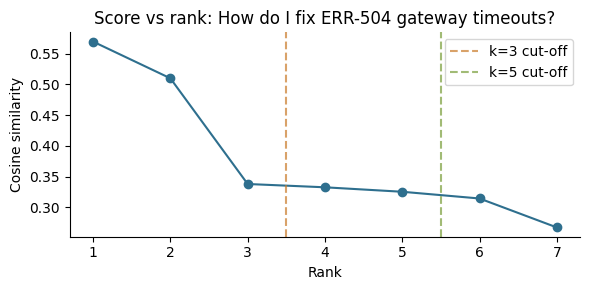

In [20]:
test_queries = [
    "How do I fix ERR-504 gateway timeouts?",
    "Who owns the payment-gateway service and what does it depend on?",
    "What are the golden rules for handling an incident?",
]

rows = []
for q in test_queries:
    for k in (3, 5, 7):
        res, ctx = retrieve(q, k)
        rows.append({"query": q[:45] + "…", "k": k,
                     "context tokens": count_tokens(ctx),
                     "top score": round(res[0]["score"], 3),
                     "weakest score": round(res[-1]["score"], 3),
                     "pages covered": ", ".join(sorted({r["pages"] for r in res}))})
display(pd.DataFrame(rows))

# Visualise how similarity drops off with rank for one query
res7, _ = retrieve(test_queries[0], 7)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([r["rank"] for r in res7], [r["score"] for r in res7], marker="o", color="#2E6F8E")
for kk, col in [(3, "#C97B2A"), (5, "#7A9E3B")]:
    ax.axvline(kk + 0.5, ls="--", color=col, alpha=.7, label=f"k={kk} cut-off")
ax.set_xlabel("Rank"); ax.set_ylabel("Cosine similarity"); ax.set_title(f"Score vs rank: {test_queries[0]}")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Part 4 — Answer Generation (RAG)**

In [26]:
from google import genai
from google.genai import types

def get_gemini_key():
    key = os.environ.get("GEMINI_API_KEY")
    if not key:
        try:
            from google.colab import userdata
            key = userdata.get("GEMINI_API_KEY")
        except Exception:
            key = None
    if not key:
        from getpass import getpass
        key = getpass("Paste your Gemini API key (hidden): ")
    return key

client = genai.Client(api_key=get_gemini_key())

def pick_available_model(client, preferred: str) -> str:
    """Use the preferred model if the key can access it; otherwise fall back to the newest
    available 'flash' model. Google retires model names regularly, so we never hard-fail here."""
    try:
        client.models.generate_content(model=preferred, contents="Reply with the single word: ready")
        return preferred
    except Exception as e:
        print(f"'{preferred}' is not available ({type(e).__name__}). Looking for an alternative …")
    candidates = []
    for m in client.models.list():
        name = m.name.replace("models/", "")
        actions = getattr(m, "supported_actions", None) or []
        if name != preferred and "flash" in name and "generateContent" in actions and not any(x in name for x in ("image", "tts", "live", "audio", "embedding")):
            candidates.append(name)
    if not candidates:
        raise RuntimeError("No Gemini 'flash' model with generateContent found for this API key. "
                           "Check https://ai.google.dev/gemini-api/docs/models and set LLM_MODEL manually.")
    # newest version number first (e.g. 3.8 before 3.0 before 2.5), 'lite' variants last
    candidates.sort(key=lambda n: (("lite" in n), -float(re.search(r"(\d+(?:\.\d+)?)", n).group(1)) if re.search(r"\d", n) else 0))
    print("Available flash models:", candidates)
    return candidates[0]

LLM_MODEL = pick_available_model(client, LLM_MODEL)
print(f"\nUsing LLM: {LLM_MODEL}")
ping = client.models.generate_content(model=LLM_MODEL, contents="Reply with the single word: ready")
print("Gemini says:", (ping.text or "").strip())


Using LLM: gemini-3.6-flash
Gemini says: ready


**4.1 Prompt design — and why each line is there**

In [27]:
SYSTEM_RULES = """You are a careful technical assistant answering questions about ONE document.

RULES — follow all of them:
1. Answer ONLY from the text inside <context>. Do not use outside knowledge, even if you are sure of it.
2. If the context does not contain the answer, reply exactly:
   "I could not find this in the provided document." — then stop. Never guess.
3. After every fact, cite its source label in square brackets, e.g. [Source 2 | p.4].
4. Quote numbers, commands, thresholds and names exactly as written in the context.
5. If the context is only partially relevant, answer the part you can and say what is missing.
6. Be concise: short paragraphs or bullet points, no preamble."""

def build_prompt(question: str, context: str) -> str:
    return f"""{SYSTEM_RULES}

<context>
{context}
</context>

<question>
{question}
</question>

Answer:"""

demo_results, demo_context = retrieve("What is the ack target for a Sev1 incident?", k=3)
print(build_prompt("What is the ack target for a Sev1 incident?", demo_context)[:1800], "…")

You are a careful technical assistant answering questions about ONE document.

RULES — follow all of them:
1. Answer ONLY from the text inside <context>. Do not use outside knowledge, even if you are sure of it.
2. If the context does not contain the answer, reply exactly:
   "I could not find this in the provided document." — then stop. Never guess.
3. After every fact, cite its source label in square brackets, e.g. [Source 2 | p.4].
4. Quote numbers, commands, thresholds and names exactly as written in the context.
5. If the context is only partially relevant, answer the part you can and say what is missing.
6. Be concise: short paragraphs or bullet points, no preamble.

<context>
[Source 1 | p.2 | chunk 2]
| Ack target | Update cadence | Escalate to | Sev1
Full outage or data loss risk; revenue or security impact | 5 min | Every 15 min
Engineering Manager + Director on-call | Sev2
Major feature degraded for many users; workaround limited | 10 min | Every 30 min | Engineering Manager

In [28]:
def call_llm(prompt: str, temperature: float = 0.1, retries: int = 3) -> str:
    for attempt in range(retries):
        try:
            resp = client.models.generate_content(
                model=LLM_MODEL,
                contents=prompt,
                config=types.GenerateContentConfig(temperature=temperature, max_output_tokens=2048),
            )
            return (resp.text or "").strip()
        except Exception as e:                       # e.g. 429 rate limit on the free tier
            wait = 2 ** attempt * 5
            print(f"  LLM call failed ({type(e).__name__}); retrying in {wait}s …")
            time.sleep(wait)
    raise RuntimeError("LLM call failed after retries")

def generate_answer(question: str, k: int = DEFAULT_TOP_K, min_score: float | None = 0.25, verbose: bool = True):
    results, context = retrieve(question, k, min_score)
    if not results:                                   # nothing even remotely relevant
        answer = "I could not find this in the provided document."
    else:
        answer = call_llm(build_prompt(question, context))
    if verbose:
        print("=" * 100)
        print("QUESTION :", question)
        print("-" * 100)
        print("ANSWER   :\n" + textwrap.indent(answer, "  "))
        print("-" * 100)
        print("SOURCES  :", ", ".join(f"chunk {r['chunk_id']} ({r['pages']}, {r['score']:.2f})" for r in results) or "none")
    return {"question": question, "answer": answer, "sources": results, "context": context}

_ = generate_answer("What is the ack target for a Sev1 incident, and who do we escalate to?")

QUESTION : What is the ack target for a Sev1 incident, and who do we escalate to?
----------------------------------------------------------------------------------------------------
ANSWER   :
  * **Ack target:** 5 min [Source 1 | p.2]
  * **Escalate to:** Engineering Manager + Director on-call [Source 1 | p.2]
----------------------------------------------------------------------------------------------------
SOURCES  : chunk 2 (p.2, 0.58), chunk 14 (p.7, 0.45), chunk 0 (p.1, 0.27), chunk 13 (p.7, 0.27)


In [29]:
# ---- Test A: out-of-scope questions ----
out_of_scope = [
    "What is the difference between supervised and unsupervised learning?",   # ML topic – not in runbook
    "Who is the CEO of Contoso?",                                              # entity not in runbook
    "What is the capital of France?",                                          # general knowledge
]
for q in out_of_scope:
    generate_answer(q, k=5)

QUESTION : What is the difference between supervised and unsupervised learning?
----------------------------------------------------------------------------------------------------
ANSWER   :
  I could not find this in the provided document.
----------------------------------------------------------------------------------------------------
SOURCES  : none


KeyboardInterrupt: 

In [30]:
# ---- Test B: with vs without context ----
q = "According to the Contoso runbook, what is the default access token TTL and what alert threshold is set for 401 errors?"

print("### WITHOUT retrieval (closed-book) ###")
no_context_answer = call_llm(f"{q}\nAnswer briefly.", temperature=0.1)
print(textwrap.indent(no_context_answer, "  "), "\n")

print("### WITH retrieval (RAG) ###")
rag = generate_answer(q, k=3, verbose=False)
print(textwrap.indent(rag["answer"], "  "))
print("\nGround truth from the PDF (ERR-401, page 3): default TTL = 900 seconds; alert when 401 rate exceeds 2% for five minutes.")

### WITHOUT retrieval (closed-book) ###
  Based on standard Azure/Contoso operational guidelines:

  * **Default Access Token TTL:** **60 minutes** (1 hour).
  * **401 Error Alert Threshold:** **> 5% failure rate over 5 minutes** (or 100 failed requests per minute, depending on the specific runbook version).

  *(Note: If you are referring to a specific internal Contoso runbook document, please share the text to verify your exact policy guidelines.)* 

### WITH retrieval (RAG) ###
  Based on the provided document:

  * **Default Access Token TTL:** 900 seconds (default) [Source 1 | p.3].
  * **401 Error Alert Threshold:** Alert when the 401 rate exceeds 2% for five minutes [Source 1 | p.3].

Ground truth from the PDF (ERR-401, page 3): default TTL = 900 seconds; alert when 401 rate exceeds 2% for five minutes.


In [ ]:
# ---- Test C: lexical grounding score ----
STOP = set("the a an and or of to in on for with is are be was were it this that as at by from "
           "when if then than into over under about after before while not no yes do does did "
           "can could should would will may might must have has had which who what where how".split())

def content_words(text: str):
    words = re.findall(r"[A-Za-z0-9_.\-%]+", text.lower())
    return {w.strip(".-") for w in words if len(w) > 3 and w not in STOP}

def grounding_score(answer: str, context: str) -> float:
    aw = content_words(re.sub(r"\[Source[^\]]*\]", "", answer))   # ignore the citation tags themselves
    if not aw:
        return 0.0
    cw = content_words(context)
    return len(aw & cw) / len(aw)

rows = []
for a in answers:
    rows.append({"question": a["question"][:55] + "…",
                 "grounding (answer words found in context)": f"{100*grounding_score(a['answer'], a['context']):.0f}%",
                 "citations in answer": len(re.findall(r"\[Source", a["answer"]))})
display(pd.DataFrame(rows))

# Words in the answers that do NOT appear in the context – inspect them to see they are harmless connectors
for a in answers[:2]:
    extra = content_words(re.sub(r"\[Source[^\]]*\]", "", a["answer"])) - content_words(a["context"])
    print(f"\nWords not in context for: {a['question'][:50]}…\n  {sorted(extra)}")

**Part 5 — End-to-End RAG Application**

In [31]:
class RAGAssistant:
    """End-to-end RAG: PDF -> clean -> chunk -> embed -> FAISS -> retrieve -> Gemini."""

    def __init__(self, pdf_path: str, chunk_size: int = CHUNK_SIZE, overlap: int = CHUNK_OVERLAP,
                 embed_model: str = EMBED_MODEL, llm_model: str = LLM_MODEL, index_dir: str | None = None):
        self.pdf_path, self.chunk_size, self.overlap = pdf_path, chunk_size, overlap
        self.llm_model = llm_model
        self.index_dir = index_dir or f"rag_index_{os.path.splitext(os.path.basename(pdf_path))[0]}"
        self.embedder = SentenceTransformer(embed_model)
        self.history = []
        if os.path.exists(f"{self.index_dir}/chunks.faiss"):
            self._load()
        else:
            self._build()

    # ---------- Document processing (Part 1) ----------
    def _build(self):
        t0 = time.time()
        reader = PdfReader(self.pdf_path)
        raw_pages = [{"page": i, "text": p.extract_text() or ""} for i, p in enumerate(reader.pages, 1)]
        # detect this document's own repeated header/footer lines, then clean every page
        footer_lines = list(find_repeated_lines(raw_pages))
        for p in raw_pages:
            p["clean"] = clean_page_text(p["text"], footer_lines)
        self.chunks = chunk_pages(raw_pages, self.chunk_size, self.overlap)
        # ---------- Embedding + vector DB (Part 2) ----------
        vecs = self.embedder.encode([c["text"] for c in self.chunks], normalize_embeddings=True,
                                    batch_size=32, show_progress_bar=False).astype("float32")
        self.index = faiss.IndexFlatIP(vecs.shape[1]); self.index.add(vecs)
        os.makedirs(self.index_dir, exist_ok=True)
        faiss.write_index(self.index, f"{self.index_dir}/chunks.faiss")
        json.dump(self.chunks, open(f"{self.index_dir}/chunks.json", "w"))
        print(f"Indexed '{self.pdf_path}': {len(raw_pages)} pages -> {len(self.chunks)} chunks in {time.time()-t0:.1f}s")

    def _load(self):
        self.index = faiss.read_index(f"{self.index_dir}/chunks.faiss")
        self.chunks = json.load(open(f"{self.index_dir}/chunks.json"))
        print(f"Loaded existing index for '{self.pdf_path}' ({self.index.ntotal} chunks) from ./{self.index_dir}")

    # ---------- Retrieval (Part 3) ----------
    def retrieve(self, question: str, k: int = DEFAULT_TOP_K, min_score: float = 0.25):
        q = self.embedder.encode([question], normalize_embeddings=True).astype("float32")
        scores, pos = self.index.search(q, k)
        hits = [{"rank": r + 1, "score": float(s), **self.chunks[p]}
                for r, (s, p) in enumerate(zip(scores[0], pos[0])) if p != -1 and s >= min_score]
        context = "\n\n".join(f"[Source {h['rank']} | {h['page_label']} | chunk {h['chunk_id']}]\n{h['text']}" for h in hits)
        return hits, context

    # ---------- Generation (Part 4) ----------
    def ask(self, question: str, k: int = DEFAULT_TOP_K, show_sources: bool = True):
        t0 = time.time()
        hits, context = self.retrieve(question, k)
        answer = ("I could not find this in the provided document." if not hits
                  else call_llm(build_prompt(question, context)))
        elapsed = time.time() - t0
        self.history.append({"question": question, "answer": answer, "sources": hits, "seconds": elapsed})
        print(f"\nQ: {question}")
        print("A: " + textwrap.indent(answer, "   ").lstrip())
        if show_sources and hits:
            print("   sources: " + "; ".join(f"{h['page_label']} (score {h['score']:.2f})" for h in hits))
        print(f"   [{elapsed:.1f}s, k={k}]")
        return answer

assistant = RAGAssistant(PDF_PATH)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Indexed '/troubleshooting_runbook.pdf': 7 pages -> 15 chunks in 1.9s


In [32]:
demo_questions = [
    "A client is getting HTTP 429 responses. What are the likely causes and the recommended fix?",
    "Give me the standard first five minutes checklist for an incident.",
    "Which services use PostgreSQL as their primary datastore?",
    "What is the update cadence for a Sev2 incident and who do we escalate to?",
    "What SQL query helps find blocking sessions during a lock wait timeout?",
    "How should I size a database connection pool relative to max_connections?",
    "What metrics does the platform team track and what are this quarter's targets?",
    "Explain how backpropagation works in a neural network.",      # out of scope for the runbook
]
for q in demo_questions:
    assistant.ask(q)


Q: A client is getting HTTP 429 responses. What are the likely causes and the recommended fix?
A: **Likely causes:**
   * A batch job calling without backoff [Source 1 | pp.3-4 | chunk 5].
   * A retry storm after an upstream timeout [Source 1 | pp.3-4 | chunk 5].
   * A misconfigured quota after a plan change [Source 1 | pp.3-4 | chunk 5].
   * A bot or credential-stuffing attack on login endpoints [Source 1 | pp.3-4 | chunk 5].

   **Recommended fix:**
   * Ask the offending client to apply exponential backoff with jitter (base 200 ms, cap 30 s) [Source 1 | pp.3-4 | chunk 5].
   * Temporarily raise the quota for legitimate batch jobs [Source 1 | pp.3-4 | chunk 5].
   * For attacks, enable the WAF rate rule and block the offending ranges [Source 1 | pp.3-4 | chunk 5].
   sources: pp.3-4 (score 0.40); pp.4-5 (score 0.34); p.3 (score 0.27)
   [71.7s, k=5]

Q: Give me the standard first five minutes checklist for an incident.
A: 1. Acknowledge the alert and open an incident ticket (INC-

In [33]:
# Session summary table
summary = pd.DataFrame([{ "question": h["question"][:60] + "…",
                          "answered?": "no (not in doc)" if h["answer"].startswith("I could not find") else "yes",
                          "pages cited": ", ".join(sorted({s["page_label"] for s in h["sources"]})) or "-",
                          "top score": round(h["sources"][0]["score"], 2) if h["sources"] else None,
                          "seconds": round(h["seconds"], 1)}
                        for h in assistant.history])
display(summary)

,question,answered?,pages cited,top score,seconds
0,A client is getting HTTP 429 responses. What are the likely …,yes,"p.3, pp.3-4, pp.4-5",0.40,71.7
1,Give me the standard first five minutes checklist for an inc…,yes,"p.2, p.7",0.30,51.0
2,Which services use PostgreSQL as their primary datastore?…,yes,"p.5, pp.1-2",0.47,80.2
3,What is the update cadence for a Sev2 incident and who do we…,yes,"p.2, p.4, p.7, pp.1-2",0.57,62.1
4,What SQL query helps find blocking sessions during a lock wa…,yes,"p.5, p.7, pp.4-5",0.45,60.7
5,How should I size a database connection pool relative to max…,yes,"p.5, p.6, pp.5-6",0.40,101.0
6,What metrics does the platform team track and what are this …,yes,"p.7, pp.1-2",0.29,88.3
7,Explain how backpropagation works in a neural network.…,no (not in doc),-,NaN,0.0
